# Decision Trees (for regression)

# when the target/output is continuous (numerical) instead of categorical (like predicting house price, temperature, or salary).

In [8]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [10]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# -------------------------
# Sample dataset (House Size (sqft) vs Price)
data = {
    'House_Size': [500, 750, 1000, 1250, 1500, 1750, 2000],
    'Price': [150000, 200000, 250000, 275000, 300000, 325000, 350000]
}

df = pd.DataFrame(data)

In [11]:
df

,House_Size,Price
0,500,150000
1,750,200000
2,1000,250000
3,1250,275000
4,1500,300000
5,1750,325000
6,2000,350000


In [12]:
# Features (X) and Target (y)
X = df[['House_Size']]
y = df['Price']

# -------------------------
# Train a Decision Tree Regressor
model = DecisionTreeRegressor(max_depth=5, random_state=42)
model.fit(X, y)

DecisionTreeRegressor(max_depth=5, random_state=42)

In [13]:
# -------------------------
# Predict for a new house size
new_house = [[1350]]
predicted_price = model.predict(new_house)

print(f"Predicted Price for house size {new_house[0][0]} sq.ft: Rs. {predicted_price[0]:,.0f}")

Predicted Price for house size 1350 sq.ft: Rs. 275,000


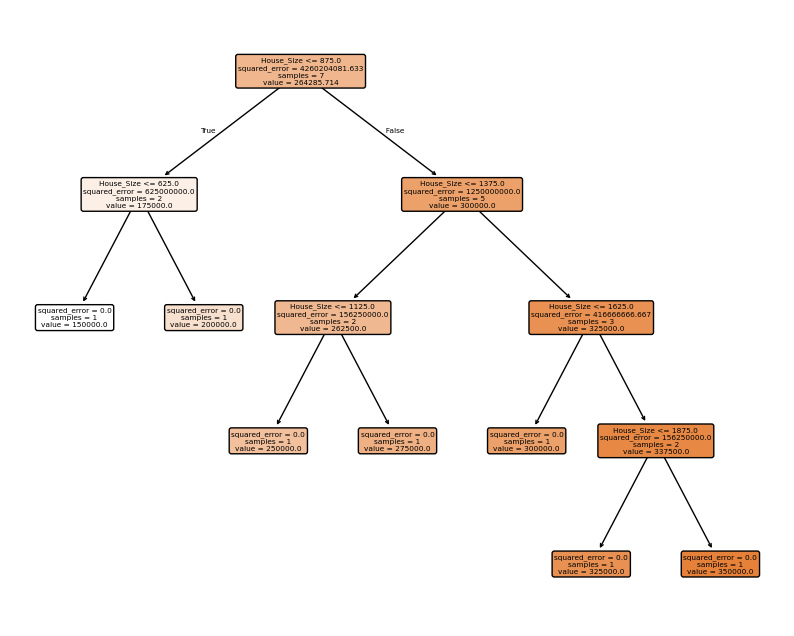

In [14]:
# ------------------------------------------------------------------------------------------
# Visualize the Decision Tree
plt.figure(figsize=(10,8))
plot_tree(model, feature_names=['House_Size'], filled=True, rounded=True)
plt.show()

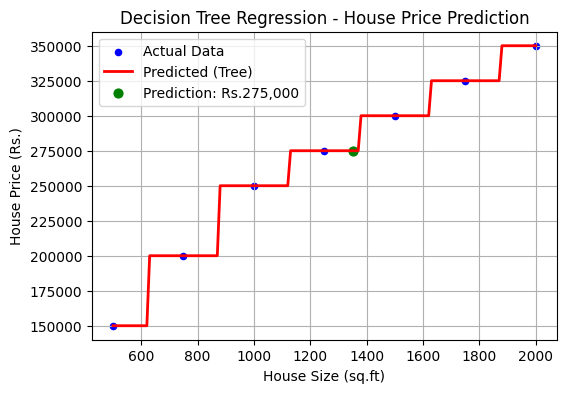

In [15]:
import numpy as np

# Plot Predicted Curve vs Actual Data
house_range = np.arange(500, 2001, 10).reshape(-1, 1)   # Range of house sizes
predictions = model.predict(house_range)

plt.figure(figsize=(6,4))
plt.scatter(X, y, color="blue", label="Actual Data", s=20)   # Actual data
plt.plot(house_range, predictions, color="red", linewidth=2, label="Predicted (Tree)")  # Stepwise prediction
plt.scatter(new_house, predicted_price, color="green", s=40, label=f"Prediction: Rs.{predicted_price[0]:,.0f}")

plt.xlabel("House Size (sq.ft)")
plt.ylabel("House Price (Rs.)")
plt.title("Decision Tree Regression - House Price Prediction")
plt.legend()
plt.grid(True)
plt.show()